# Task 4: Classification with Logistic Regression

## Objective
Build a binary classification model using Logistic Regression.

## Project Workflow
1. Load the dataset
2. Perform Exploratory Data Analysis (EDA)
3. Prepare features and target
4. Split data into training, validation, and testing sets
5. Standardize features
6. Train Logistic Regression
7. Evaluate model performance
8. Visualize the Confusion Matrix and ROC Curve
9. Tune the classification threshold
10. Explain the Sigmoid Function

## 1. Import and Load Dataset

We will use the Breast Cancer Wisconsin Diagnostic dataset from Scikit-learn.

This is a binary classification dataset.

- 0 = Malignant (Cancerous)
- 1 = Benign (Non-cancerous)

For this project, we will reverse the labels so that:
- 1 = Malignant (Positive class)
- 0 = Benign (Negative class)

In [6]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load dataset
dataset = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(
    dataset.data,
    columns=dataset.feature_names
)

# Reverse target labels
df["diagnosis"] = (dataset.target == 0).astype(int)

# Display first five rows
df.tail(10)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
559,11.51,23.93,74.52,403.5,0.09261,0.10210,0.11120,0.04105,0.1388,0.06570,...,37.16,82.28,474.2,0.12980,0.25170,0.3630,0.09653,0.2112,0.08732,0
560,14.05,27.15,91.38,600.4,0.09929,0.11260,0.04462,0.04304,0.1537,0.06171,...,33.17,100.20,706.7,0.12410,0.22640,0.1326,0.10480,0.2250,0.08321,0
561,11.20,29.37,70.67,386.0,0.07449,0.03558,0.00000,0.00000,0.1060,0.05502,...,38.30,75.19,439.6,0.09267,0.05494,0.0000,0.00000,0.1566,0.05905,0
562,15.22,30.62,103.40,716.9,0.10480,0.20870,0.25500,0.09429,0.2128,0.07152,...,42.79,128.70,915.0,0.14170,0.79170,1.1700,0.23560,0.4089,0.14090,1
563,20.92,25.09,143.00,1347.0,0.10990,0.22360,0.31740,0.14740,0.2149,0.06879,...,29.41,179.10,1819.0,0.14070,0.41860,0.6599,0.25420,0.2929,0.09873,1
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.22160,0.2060,0.07115,1
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.16280,0.2572,0.06637,1
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.14180,0.2218,0.07820,1
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.26500,0.4087,0.12400,1
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.00000,0.2871,0.07039,0


In [7]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

Dataset Shape: (569, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  s

In [8]:
# Statistical summary
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.372583
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,0.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [9]:
# Check missing values
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
diagnosis                  0
dtype: int64

In [10]:
# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


diagnosis
0    357
1    212
Name: count, dtype: int64


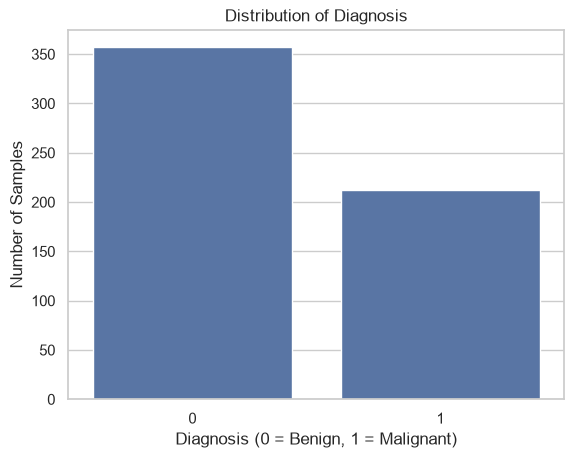

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count the number of samples in each class
print(df["diagnosis"].value_counts())

# Visualize class distribution
sns.countplot(data=df, x="diagnosis")

plt.title("Distribution of Diagnosis")
plt.xlabel("Diagnosis (0 = Benign, 1 = Malignant)")
plt.ylabel("Number of Samples")
plt.show()

In [12]:
# Separate input features and target variable
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


In [13]:
from sklearn.model_selection import train_test_split

# First split: 60% training and 40% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Second split: 20% validation and 20% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))


Training Samples: 341
Validation Samples: 114
Testing Samples: 114


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a machine learning pipeline
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [16]:
# Predict class labels
y_pred = model.predict(X_test)

# Predict probabilities for the positive class
y_prob = model.predict_proba(X_test)[:, 1]

print("Predicted Labels:", y_pred[:10])
print("Predicted Probabilities:", y_prob[:10])

Predicted Labels: [0 0 0 0 0 0 0 0 0 1]
Predicted Probabilities: [5.53119224e-03 2.37819420e-02 3.90452997e-03 6.69052113e-05
 1.82625377e-03 5.21989608e-02 2.21275133e-03 1.90354658e-01
 3.90621715e-05 9.99135787e-01]


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.9649122807017544
Precision: 1.0
Recall   : 0.9047619047619048
F1-Score : 0.95

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        72
           1       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



## 8. Confusion Matrix

A confusion matrix compares actual labels with predicted labels.

It contains:

- True Positive (TP)
- True Negative (TN)
- False Positive (FP)
- False Negative (FN)

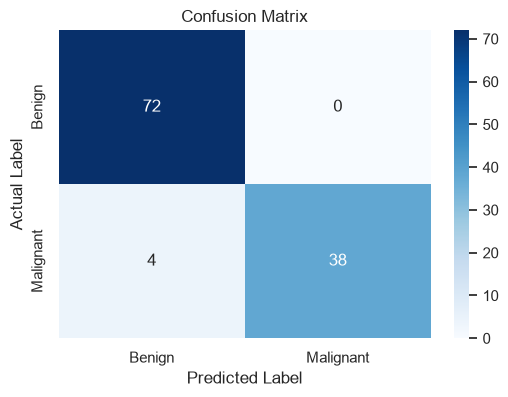

In [18]:
from sklearn.metrics import confusion_matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

## 9. ROC Curve and ROC-AUC

ROC stands for Receiver Operating Characteristic.

The ROC curve illustrates the relationship between:

- True Positive Rate (TPR)
- False Positive Rate (FPR)

ROC-AUC measures how well the model distinguishes between two classes.

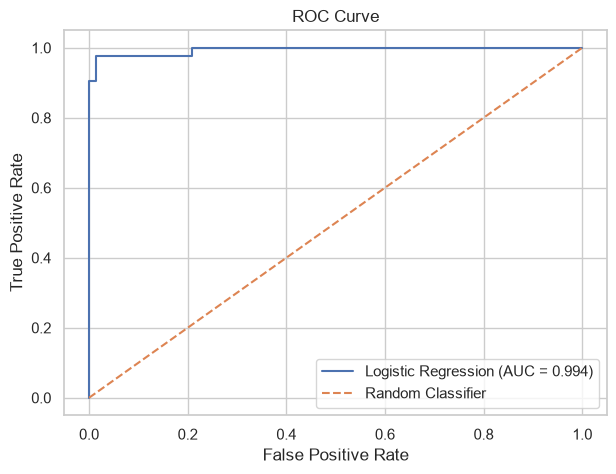

ROC-AUC Score: 0.9940476190476191


In [19]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC score
roc_auc = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("ROC-AUC Score:", roc_auc)

## 10. Classification Threshold Tuning

By default, Logistic Regression uses a threshold of 0.5.

If the predicted probability is:
- >= 0.5: Predict class 1
- < 0.5: Predict class 0

We will experiment with different thresholds and select the one that gives the highest F1-score on the validation dataset.

The test dataset will remain untouched during threshold selection.

In [20]:
import numpy as np

# Get validation probabilities
y_val_prob = model.predict_proba(X_val)[:, 1]

# Try different thresholds
thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_val_pred = (y_val_prob >= threshold).astype(int)

    # Calculate metrics
    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Display results
threshold_df = pd.DataFrame(results)

threshold_df

,Threshold,Precision,Recall,F1-Score
0,0.10,0.955556,1.000000,0.977273
1,0.15,0.977273,1.000000,0.988506
2,0.20,0.977273,1.000000,0.988506
3,0.25,0.977273,1.000000,0.988506
4,0.30,1.000000,0.976744,0.988235
5,0.35,1.000000,0.953488,0.976190
6,0.40,1.000000,0.953488,0.976190
7,0.45,1.000000,0.953488,0.976190
8,0.50,1.000000,0.930233,0.963855
9,0.55,1.000000,0.906977,0.951220


In [21]:
# Find the threshold with the highest validation F1-score
best_index = threshold_df["F1-Score"].idxmax()

best_threshold = threshold_df.loc[best_index, "Threshold"]

print("Best Threshold:", best_threshold)
print("Best Validation F1-Score:", threshold_df.loc[best_index, "F1-Score"])

Best Threshold: 0.15000000000000002
Best Validation F1-Score: 0.9885057471264368


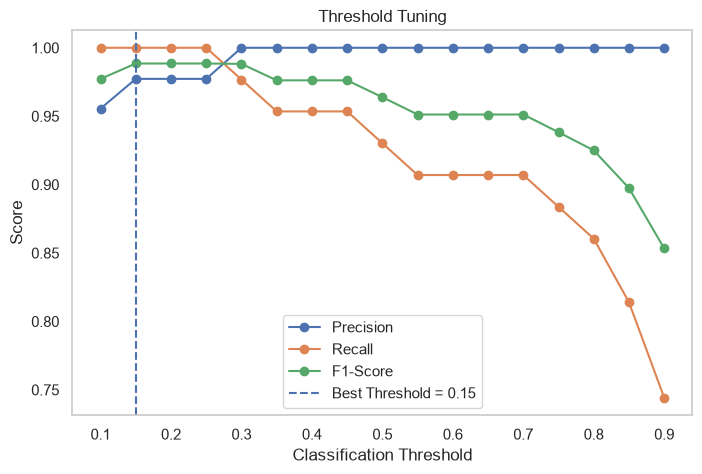

In [22]:
# Visualize threshold performance
plt.figure(figsize=(8, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Tuning")
plt.legend()
plt.grid()
plt.show()

## 11. Final Evaluation with Tuned Threshold

We will now apply the selected validation threshold to the test dataset.

This provides a fair final evaluation without using test data to choose the threshold.

In [23]:
# Apply tuned threshold to test probabilities
y_test_tuned = (y_prob >= best_threshold).astype(int)

# Evaluate tuned predictions
print("Tuned Threshold:", best_threshold)

print("Accuracy :", accuracy_score(y_test, y_test_tuned))
print("Precision:", precision_score(y_test, y_test_tuned))
print("Recall   :", recall_score(y_test, y_test_tuned))
print("F1-Score :", f1_score(y_test, y_test_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_test_tuned))

Tuned Threshold: 0.15000000000000002
Accuracy : 0.9473684210526315
Precision: 0.8913043478260869
Recall   : 0.9761904761904762
F1-Score : 0.9318181818181818

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.93      0.96        72
           1       0.89      0.98      0.93        42

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.94       114
weighted avg       0.95      0.95      0.95       114



## 12. Sigmoid Function

Logistic Regression uses the sigmoid function to convert a linear output into a probability between 0 and 1.

Formula:

σ(z) = 1 / (1 + e^(-z))

Where:
- z = weighted sum of input features + bias
- e = Euler's number
- σ(z) = predicted probability

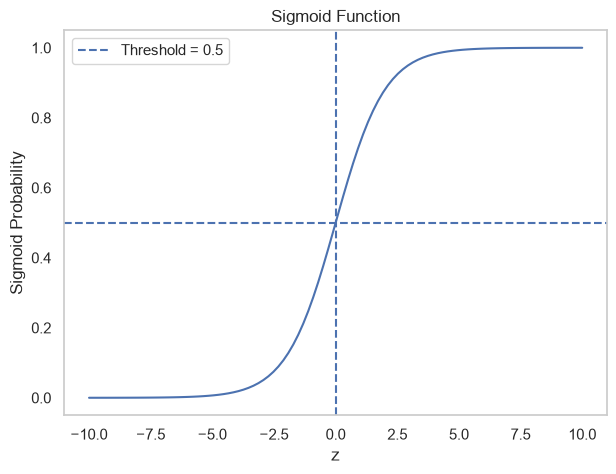

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Define sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Generate values
z = np.linspace(-10, 10, 100)

# Calculate sigmoid outputs
probabilities = sigmoid(z)

# Plot sigmoid curve
plt.figure(figsize=(7, 5))

plt.plot(z, probabilities)

plt.axhline(0.5, linestyle="--", label="Threshold = 0.5")
plt.axvline(0, linestyle="--")

plt.xlabel("z")
plt.ylabel("Sigmoid Probability")
plt.title("Sigmoid Function")
plt.legend()
plt.grid()
plt.show()